In [1]:
# ================================================================
# 1. INSTALL REQUIRED LIBRARIES (Kaggle Environment)
# ================================================================
!pip install -q opensmile lightgbm xgboost scikit-learn pandas tqdm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 11.9 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.9/74.9 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 133.7/133.7 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 325.0/325.0 kB 23.0 MB/s eta 0:00:00


In [2]:
import os
import pandas as pd
import numpy as np
import opensmile
from tqdm.auto import tqdm

# ================================================================
# 2. DATASET ROUTING
# Kaggle automatically unzips datasets. Point this directly 
# to your attached dataset folder in the /kaggle/input/ directory.
# ================================================================
DATASET_ROOT = "/kaggle/input/datasets/cooldatascientist/caac-atc-fatigue-corpus" # UPDATE THIS to your exact Kaggle dataset slug

if not os.path.exists(DATASET_ROOT):
    raise FileNotFoundError(f"Dataset not found at {DATASET_ROOT}. Please check your attached inputs.")

# ================================================================
# 3. INITIALIZE OPENSMILE
# ================================================================
print("Initializing OpenSMILE eGeMAPSv02 feature set...")
smile = opensmile.Smile(
    feature_set=opensmile.FeatureSet.eGeMAPSv02,
    feature_level=opensmile.FeatureLevel.Functionals,
)

features = []
labels = []

Initializing OpenSMILE eGeMAPSv02 feature set...


In [3]:
# ================================================================
# 4. FUNCTION FOR FEATURE EXTRACTION
# ================================================================
def process_folder(folder_path, label):
    files = [f for f in os.listdir(folder_path) if f.endswith(".wav")]
    for file in tqdm(files, desc=f"Processing {os.path.basename(folder_path)}"):
        file_path = os.path.join(folder_path, file)
        try:
            feat = smile.process_file(file_path)
            feat_vector = feat.iloc[0].values
            features.append(feat_vector)
            labels.append(label)
        except Exception as e:
            print(f"Error processing {file_path}: {e}")

# ================================================================
# 5. LOOP THROUGH ALL DATASETS
# ================================================================
for dataset in os.listdir(DATASET_ROOT):
    dataset_path = os.path.join(DATASET_ROOT, dataset)
    if not os.path.isdir(dataset_path):
        continue

    fatigue_path = os.path.join(dataset_path, "fatigue")
    nonfatigue_path = os.path.join(dataset_path, "nonfatigue")

    if os.path.exists(fatigue_path):
        print(f"Processing fatigue: {dataset}")
        process_folder(fatigue_path, 1)

    if os.path.exists(nonfatigue_path):
        print(f"Processing nonfatigue: {dataset}")
        process_folder(nonfatigue_path, 0)

# ================================================================
# 6. CREATE & SAVE FEATURE DATASET
# ================================================================
df = pd.DataFrame(features)
df["label"] = labels

print(f"Total samples extracted: {len(df)}")

# Save to working directory so you don't lose the extraction if the kernel restarts
df.to_csv("/kaggle/working/baseline_opensmile_features.csv", index=False)
print("✅ Features saved to /kaggle/working/baseline_opensmile_features.csv")

Processing fatigue: ATCs_2


Processing fatigue:   0%|          | 0/199 [00:00<?, ?it/s]

Processing nonfatigue: ATCs_2


Processing nonfatigue:   0%|          | 0/1110 [00:00<?, ?it/s]

Processing fatigue: ATCs_3_speech


...

Processing fatigue: ATCs_1_speech


Processing fatigue:   0%|          | 0/415 [00:00<?, ?it/s]

Processing nonfatigue: ATCs_1_speech


Processing nonfatigue:   0%|          | 0/1182 [00:00<?, ?it/s]

Total samples extracted: 10713
✅ Features saved to /kaggle/working/baseline_opensmile_features.csv


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc
import matplotlib.pyplot as plt

# ================================================================
# 7. DATA IMPUTATION & TRAIN/TEST SPLIT
# ================================================================
X = df.drop("label", axis=1)
y = df["label"]

# Impute NaN values (XGBoost handles NaNs natively, but SVM/RF/LightGBM do not)
imputer = SimpleImputer(strategy='mean')
X_imputed = imputer.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_imputed, 
    y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

# Scaling (Strictly required for SVM, helps convergence for others)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("✅ Data imputed, split, and scaled. Ready for training.")

# ================================================================
# 8. PLOTTING HELPER FUNCTIONS
# ================================================================
def plot_confusion_matrix(model, X_val, y_val, title):
    y_pred = model.predict(X_val)
    cm = confusion_matrix(y_val, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Non-Fatigue", "Fatigue"])
    disp.plot(cmap='Blues')
    plt.title(title)
    plt.show()

def plot_roc_curve(model, X_val, y_val, title):
    y_prob = model.predict_proba(X_val)[:, 1]
    fpr, tpr, _ = roc_curve(y_val, y_prob)
    roc_auc = auc(fpr, tpr)

    plt.figure()
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f"AUC = {roc_auc:.2f}")
    plt.plot([0,1], [0,1], color='navy', lw=2, linestyle='--')
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(title)
    plt.legend(loc="lower right")
    plt.show()

✅ Data imputed, split, and scaled. Ready for training.


TRAINING: XGBOOST
Accuracy: 0.8007466168922072
              precision    recall  f1-score   support

           0       0.84      0.93      0.88      1758
           1       0.40      0.22      0.28       385

    accuracy                           0.80      2143
   macro avg       0.62      0.57      0.58      2143
weighted avg       0.76      0.80      0.78      2143



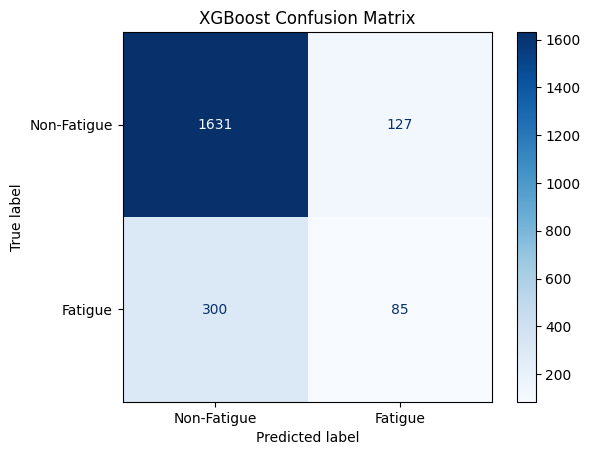

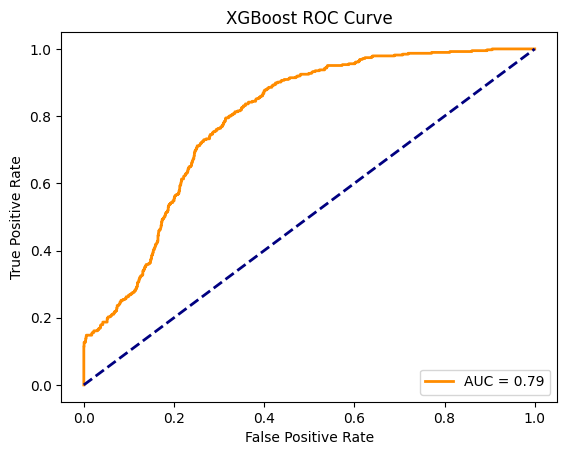

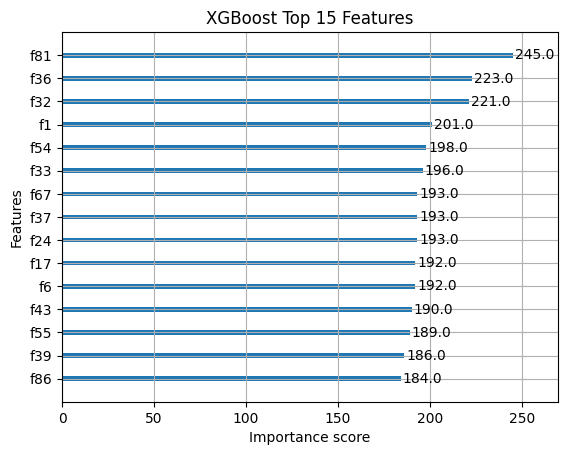

In [9]:
import xgboost as xgb

print("="*60)
print("TRAINING: XGBOOST")
print("="*60)

xgb_model = xgb.XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42
)

xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_xgb))
print(classification_report(y_test, y_pred_xgb))

plot_confusion_matrix(xgb_model, X_test, y_test, "XGBoost Confusion Matrix")
plot_roc_curve(xgb_model, X_test, y_test, "XGBoost ROC Curve")

# Feature Importance
xgb.plot_importance(xgb_model, max_num_features=15, title="XGBoost Top 15 Features")
plt.show()

TRAINING: RANDOM FOREST
Random Forest Accuracy: 0.8021465235650956
              precision    recall  f1-score   support

           0       0.84      0.93      0.89      1758
           1       0.40      0.20      0.27       385

    accuracy                           0.80      2143
   macro avg       0.62      0.57      0.58      2143
weighted avg       0.76      0.80      0.77      2143



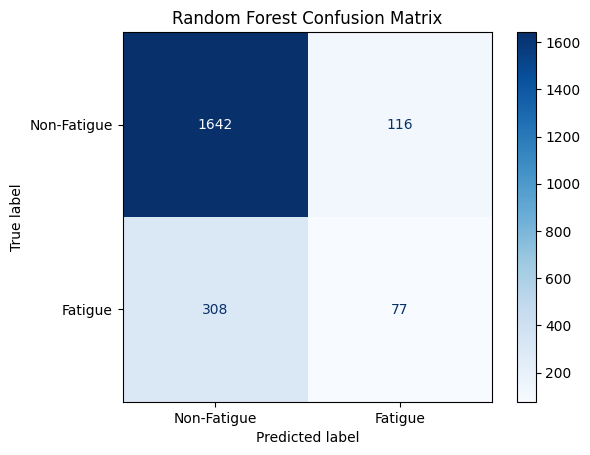

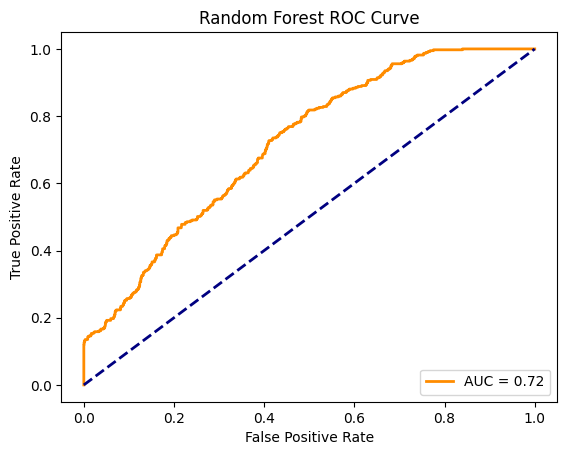

In [10]:
from sklearn.ensemble import RandomForestClassifier

print("="*60)
print("TRAINING: RANDOM FOREST")
print("="*60)

rf_model = RandomForestClassifier(
    n_estimators=400,
    max_depth=20,
    random_state=42,
    n_jobs=-1 # Utilizes all CPU cores available in Kaggle
)

rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))

plot_confusion_matrix(rf_model, X_test, y_test, "Random Forest Confusion Matrix")
plot_roc_curve(rf_model, X_test, y_test, "Random Forest ROC Curve")

TRAINING: SUPPORT VECTOR MACHINE (SVM)
SVM Accuracy: 0.8371441903873075
              precision    recall  f1-score   support

           0       0.86      0.96      0.91      1758
           1       0.60      0.28      0.38       385

    accuracy                           0.84      2143
   macro avg       0.73      0.62      0.64      2143
weighted avg       0.81      0.84      0.81      2143



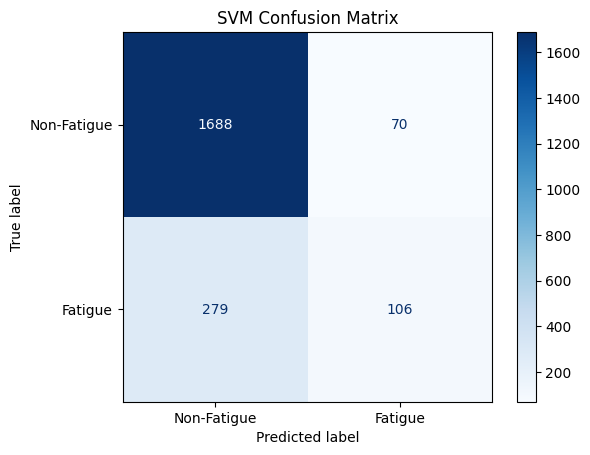

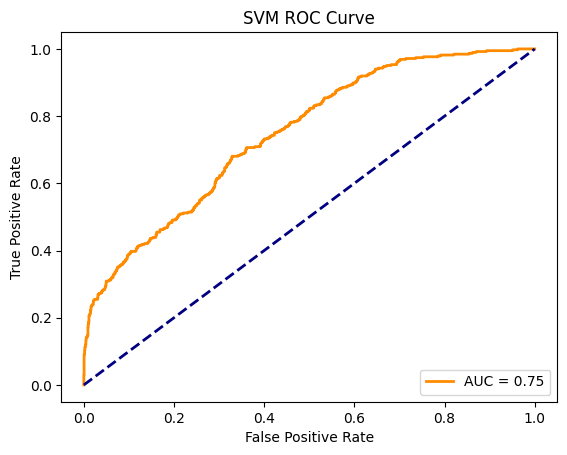

In [11]:
from sklearn.svm import SVC

print("="*60)
print("TRAINING: SUPPORT VECTOR MACHINE (SVM)")
print("="*60)

# Note: SVM explicitly uses the _scaled data variants
svm_model = SVC(
    kernel="rbf",
    C=10,
    gamma="scale",
    probability=True,
    random_state=42
)

svm_model.fit(X_train_scaled, y_train)
y_pred_svm = svm_model.predict(X_test_scaled)

print("SVM Accuracy:", accuracy_score(y_test, y_pred_svm))
print(classification_report(y_test, y_pred_svm))

plot_confusion_matrix(svm_model, X_test_scaled, y_test, "SVM Confusion Matrix")
plot_roc_curve(svm_model, X_test_scaled, y_test, "SVM ROC Curve")

TRAINING: LIGHTGBM
LightGBM Accuracy: 0.8026131591227251
              precision    recall  f1-score   support

           0       0.85      0.93      0.89      1758
           1       0.41      0.23      0.29       385

    accuracy                           0.80      2143
   macro avg       0.63      0.58      0.59      2143
weighted avg       0.77      0.80      0.78      2143



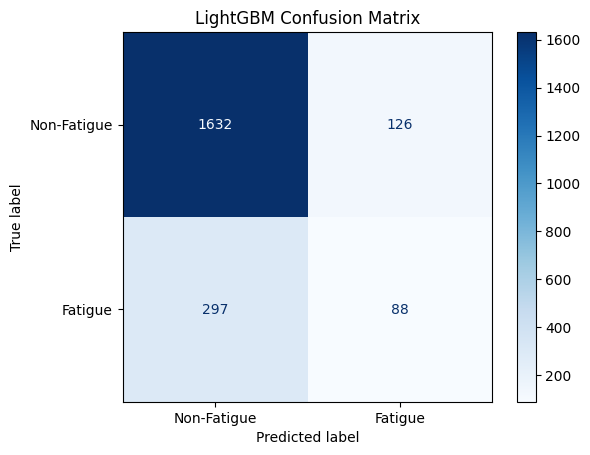

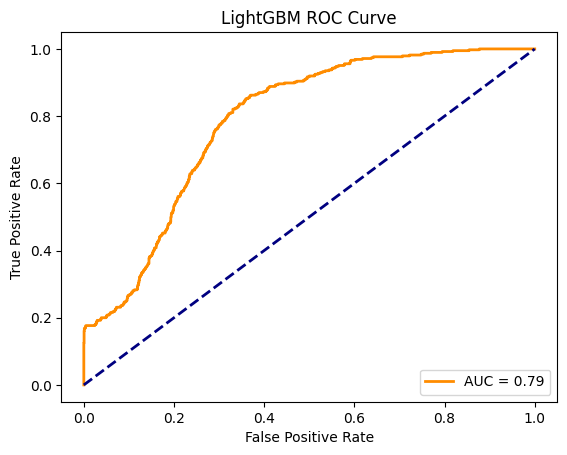

In [12]:
import lightgbm as lgb
import pandas as pd

print("="*60)
print("TRAINING: LIGHTGBM")
print("="*60)

# 1. Give the NumPy arrays explicit string column names to satisfy Scikit-Learn
feature_cols = [f"Feature_{i}" for i in range(X_train.shape[1])]
X_train_lgb = pd.DataFrame(X_train, columns=feature_cols)
X_test_lgb = pd.DataFrame(X_test, columns=feature_cols)

# 2. Add verbose=-1 to silence the native LightGBM informational logs
lgb_model = lgb.LGBMClassifier(
    n_estimators=400,
    learning_rate=0.05,
    random_state=42,
    n_jobs=-1,
    verbose=-1  
)

lgb_model.fit(X_train_lgb, y_train)
y_pred_lgb = lgb_model.predict(X_test_lgb)

print("LightGBM Accuracy:", accuracy_score(y_test, y_pred_lgb))
print(classification_report(y_test, y_pred_lgb))

# Make sure to use the new DataFrame variables (X_test_lgb) for the plotting functions too
plot_confusion_matrix(lgb_model, X_test_lgb, y_test, "LightGBM Confusion Matrix")
plot_roc_curve(lgb_model, X_test_lgb, y_test, "LightGBM ROC Curve")